# 01 · Data overview & filtering

Three walking datasets, converted to one canonical skeleton
`[L/R hip, knee, ankle, heel, toe, pelvis(mid-hip)]` and filtered by `src/build_dataset.py`.

| Dataset | Source | Capture | Unit of analysis |
|---|---|---|---|
| Fukuchi WBDS | Figshare 5722711 (CC BY) | Optical mocap 150 Hz, treadmill (8 speeds, 30 s) + overground (~2.5 s passes), force plates | trial |
| Ferber RIC | Figshare 24255795 (CC BY) | Optical mocap 120/200 Hz, treadmill, cluster markers only | session |
| Toronto OA | Figshare c.5515953 (CC0) | Xsens IMU mocap 100 Hz, overground hallway, 2D video pose | straight pass |

*This project is a prototype and is not medical advice.*

In [2]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from analysis import *
from canonical import J, JOINTS, SIDES
style()
pd.set_option("display.width", 200, "display.max_columns", 40)

In [3]:
T = pd.concat([trials(d) for d in DATASETS], ignore_index=True)
T["reject_reason"] = T.reject_reason.fillna("kept")
summary = (T.groupby("dataset")
             .agg(trials=("trial", "size"), kept=("keep", "sum"),
                  subjects=("subject", "nunique"),
                  subjects_kept=("subject", lambda s: s[T.loc[s.index, "keep"]].nunique()),
                  hours_kept=("duration_s", lambda d: d[T.loc[d.index, "keep"]].sum() / 3600))
             .reindex(DATASETS))
summary.round(2)

,trials,kept,subjects,subjects_kept,hours_kept
dataset,,,,,
fukuchi,2023,1972,51,51,4.25
ferber,2088,2061,1686,1670,22.00
toronto,51,48,14,11,0.13


## Filtering funnel
Each trial is rejected for the first rule it fails (thresholds in `build_dataset.QC`):
missing markers after ≤0.1 s gap filling (long treadmill trials are cropped to their longest clean
≥10 s stretch instead), implausible leg length, poor rigid-cluster fit (Ferber), speed outside
walking range (>2.2 m/s ⇒ likely a jog), too few valid strides, stride-time CoV > 20 % (event failure).

~40 % of Ferber sessions were recorded without any foot landmarks (no toe, no metatarsal markers).
Rather than drop them they get a **virtual foot** (`toe_source == "virtual"`, see notebook 02) —
filter on that column if you want marker-only data.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


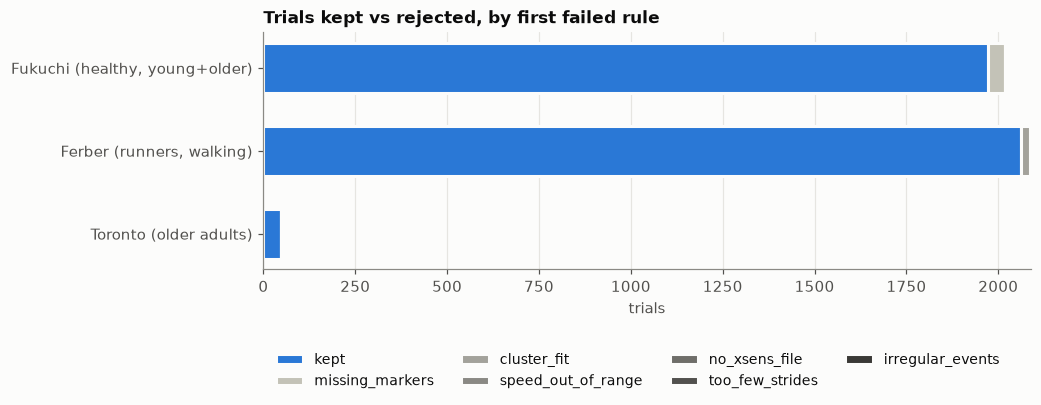

reject_reason,kept,missing_markers,cluster_fit,speed_out_of_range,no_xsens_file,too_few_strides,irregular_events
dataset,,,,,,,
fukuchi,1972,46,0,1,0,3,1
ferber,2061,0,24,3,0,0,0
toronto,48,0,0,0,3,0,0


In [3]:
reasons = T.groupby(["dataset", "reject_reason"]).size().unstack(fill_value=0).reindex(DATASETS)
order = ["kept"] + [c for c in reasons.sum().sort_values(ascending=False).index if c != "kept"]
reasons = reasons[order]
fig, ax = plt.subplots(figsize=(9, 2.8))
left = np.zeros(len(reasons))
rej_cols = ["#c3c2b7", "#a3a29b", "#8a8984", "#6f6e69", "#52514e", "#3a3936", "#262624"]
for i, c in enumerate(order):
    v = reasons[c].to_numpy()
    ax.barh(range(len(reasons)), v, left=left, height=0.6,
            color=COL_KEEP if (COL_KEEP := "#2a78d6") and c == "kept" else rej_cols[(i - 1) % len(rej_cols)],
            edgecolor=SURFACE, linewidth=2, label=c)
    left += v
ax.set_yticks(range(len(reasons)), [LABEL[d] for d in reasons.index]); ax.invert_yaxis()
ax.set_xlabel("trials"); ax.set_title("Trials kept vs rejected, by first failed rule")
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.3), fontsize=9)
ax.grid(axis="y", visible=False)
save(fig, "01_filter_funnel"); plt.show()
reasons

## Who is in the data
Population differences are the reason metrics must be reported **per dataset**.

/tmp/nix-shell.SqEfpj/ipykernel_42570/2097032947.py:17: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  sx = sx.div(sx.sum(1), axis=0) * 100


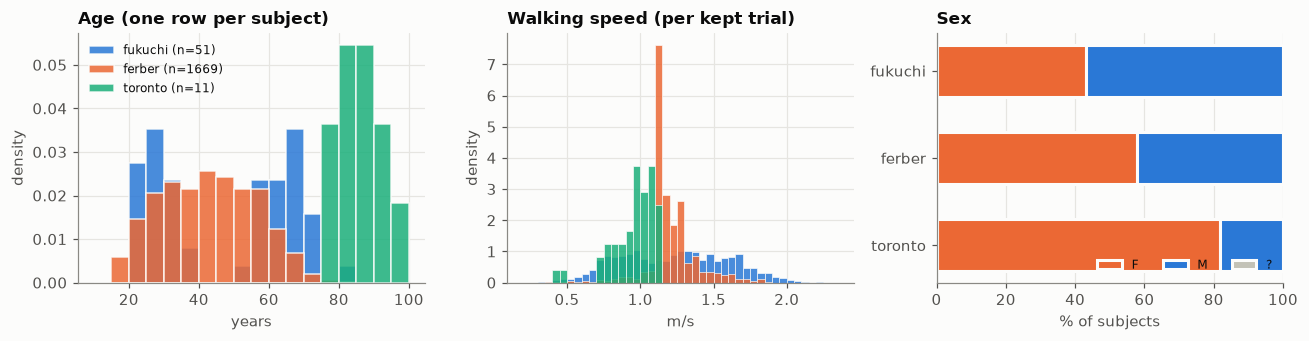

dataset          ferber  fukuchi  toronto
age       count  1669.0     51.0     11.0
          mean     42.4     47.1     86.5
          std      13.4     19.5      6.8
          min      18.0     21.0     75.0
          25%      31.0     28.0     83.0
          50%      42.0     55.0     87.0
          75%      53.0     65.5     90.5
          max      82.0     84.0     99.0
height_cm count  1663.0     51.0     11.0
          mean    171.2    167.0    165.6
          std       9.3     11.0      9.0
          min     120.0    147.0    147.3
          25%     164.6    157.4    163.2
          50%     171.0    168.0    164.5
          75%     178.0    173.6    171.5
          max     200.0    192.0    180.0
speed     count  1670.0     51.0     11.0
          mean      1.2      1.1      0.9
          std       0.2      0.3      0.2
          min       0.4      0.3      0.5
          25%       1.1      1.0      0.9
          50%       1.2      1.2      1.0
          75%       1.3      1.3      1.0
          max       1.9      1.5      1.1

In [4]:
K = all_trials()
# one row per subject (first kept trial) for demographics
S = K.sort_values("trial").groupby(["dataset", "subject"]).first().reset_index()
S["sex"] = S.sex.astype(str).str.upper().str[0].replace({"N": "?", "U": "?"})
fig, axs = plt.subplots(1, 3, figsize=(12, 3.2))
bins = np.arange(10, 101, 5)
for d in DATASETS:
    a = S.loc[S.dataset == d, "age"].dropna()
    axs[0].hist(a, bins=bins, color=COL[d], alpha=0.85, label=f"{d} (n={len(a)})", edgecolor=SURFACE, linewidth=1, density=True)
axs[0].set_title("Age (one row per subject)"); axs[0].set_ylabel("density"); axs[0].set_xlabel("years"); axs[0].legend(fontsize=8)
for d in DATASETS:
    sp = K.loc[K.dataset == d, "speed"].dropna()
    axs[1].hist(sp, bins=np.arange(0.2, 2.4, 0.05), color=COL[d], alpha=0.85, label=d, density=True,
                edgecolor=SURFACE, linewidth=0.5)
axs[1].set_title("Walking speed (per kept trial)"); axs[1].set_xlabel("m/s"); axs[1].set_ylabel("density")
sx = S.groupby(["dataset", "sex"]).size().unstack(fill_value=0).reindex(DATASETS)
sx = sx.div(sx.sum(1), axis=0) * 100
left = np.zeros(len(sx))
for c, colr in zip(["F", "M", "?"], ["#eb6834", "#2a78d6", "#c3c2b7"]):
    if c in sx:
        axs[2].barh(range(len(sx)), sx[c], left=left, color=colr, height=0.6, edgecolor=SURFACE, linewidth=2, label=c)
        left += sx[c].to_numpy()
axs[2].set_yticks(range(len(sx)), sx.index); axs[2].invert_yaxis(); axs[2].set_xlabel("% of subjects")
axs[2].set_title("Sex"); axs[2].legend(ncol=3, fontsize=8, loc="lower right"); axs[2].grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "01_demographics"); plt.show()
S.groupby("dataset")[["age", "height_cm", "speed"]].describe().round(1).T

## Fukuchi: speed protocol
Treadmill trials span 8 speeds per subject (T01–T08 as fractions of the subject's dimensionless
comfortable speed) — the dataset that gives the model speed coverage.

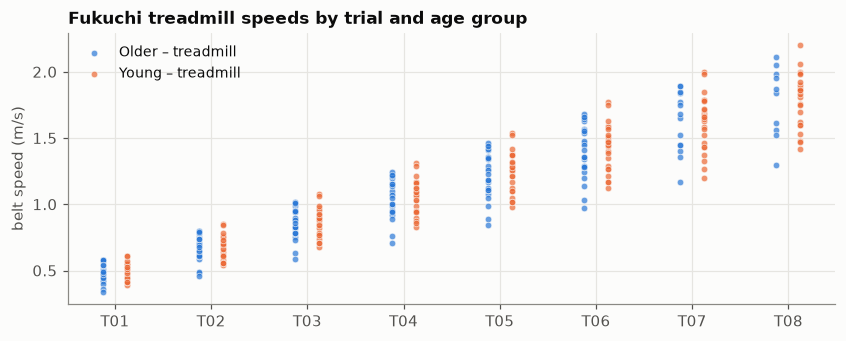

count        mean      
age_group              Older Young Older Young
mode       speed_label                        
overground comfortable   229   302  1.28  1.26
           fast          212   342  1.59  1.60
           slow          240   294  0.86  0.86
treadmill  T01            20    24  0.48  0.50
           T02            23    24  0.67  0.69
           T03            23    23  0.86  0.87
           T04            23    24  1.05  1.06
           T05            25    24  1.22  1.24
           T06            25    24  1.40  1.43
           T07            14    24  1.62  1.61
           T08            10    23  1.78  1.79

In [5]:
F = trials("fukuchi", kept_only=True)
fig, ax = plt.subplots(figsize=(9, 3.2))
for i, (grp, g) in enumerate(F.groupby("age_group")):
    tm = g[g["mode"] == "treadmill"]
    x = tm.speed_label.str[1:].astype(int) + (i - 0.5) * 0.25
    ax.scatter(x, tm.speed, s=18, color=SERIES[i], alpha=0.7, label=f"{grp} – treadmill", edgecolor=SURFACE, linewidth=0.5)
ax.set_xticks(range(1, 9), [f"T0{i}" for i in range(1, 9)]); ax.set_ylabel("belt speed (m/s)")
ax.set_title("Fukuchi treadmill speeds by trial and age group"); ax.legend(fontsize=9)
save(fig, "01_fukuchi_speeds"); plt.show()
F.groupby(["age_group", "mode", "speed_label"]).speed.agg(["count", "mean"]).round(2).unstack(0).head(12)

## Ferber: injury labels (cleaned per the dataset README)
`InjSide` is the cross-check for the symmetry head. Injured = anything other than
*No injury* in `InjDefn`/`InjJoint`/`SpecInjury`; spelling variants merged
(`oa`→`osteoarthritis`, `pfps`→`patellofemoral pain syndrome`, `itbs`→`itb syndrome`, `bi-lateral`→`bilateral`).

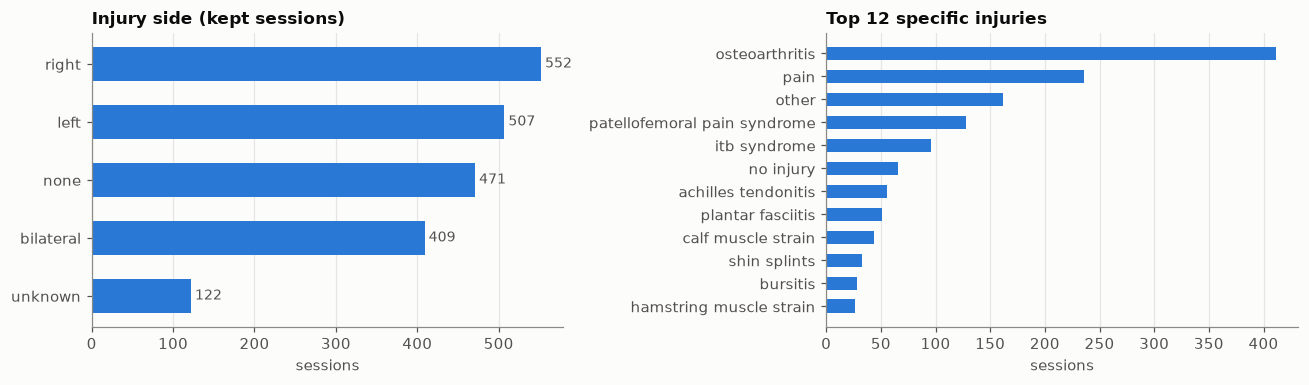

InjSide_clean,?,bilateral,left,none,right
InjJoint,,,,,
Knee,5,193,236,0,220
Thigh,4,20,75,0,42
Foot,2,37,47,0,47
Lower Leg,4,63,37,0,52
Hip/Pelvis,3,27,36,0,70
Ankle,3,19,33,0,46
Hip,0,17,24,0,42
Sacroiliac Joint,1,6,7,0,10
Lumbar Spine,4,20,7,0,14


In [6]:
R = trials("ferber", kept_only=True)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
side = R.InjSide_clean.fillna("unknown").value_counts()
axs[0].barh(side.index, side.values, color=SERIES[0], height=0.6)
axs[0].invert_yaxis(); axs[0].set_title("Injury side (kept sessions)"); axs[0].set_xlabel("sessions")
for i, v in enumerate(side.values): axs[0].text(v, i, f" {v}", va="center", color=INK2, fontsize=9)
inj = R.SpecInjury_clean.dropna().value_counts().head(12)
axs[1].barh(inj.index, inj.values, color=SERIES[0], height=0.6)
axs[1].invert_yaxis(); axs[1].set_title("Top 12 specific injuries"); axs[1].set_xlabel("sessions")
for a in axs: a.grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "01_ferber_injuries"); plt.show()
pd.crosstab(R.InjJoint.fillna("?").str.title(), R.InjSide_clean.fillna("?")).sort_values("left", ascending=False).head(10)

## Toronto: clinical scores
Only 14 participants (11 with Xsens data), POMA ceiling effects — use for qualitative checks, not
for training a clinical-score head with any confidence.

In [7]:
tor = trials("toronto")
P = tor.groupby("subject").first()
P["has_xsens"] = tor.groupby("subject").keep.any()
P[["age", "sex", "height_cm", "poma_gait", "poma_balance", "bbs", "tug_s", "falls_6mo", "has_xsens"]]

,age,sex,height_cm,poma_gait,poma_balance,bbs,tug_s,falls_6mo,has_xsens
subject,,,,,,,,,
toronto_01,84.0,F,156.0,12.0,12.0,45.0,9.00,0.0,True
toronto_02,93.0,F,147.3,11.0,14.0,46.0,10.22,0.0,True
toronto_03,92.0,F,163.5,12.0,11.0,39.0,10.38,0.0,True
toronto_04,83.0,F,152.5,12.0,14.0,53.0,8.35,0.0,False
toronto_05,89.0,F,175.0,12.0,14.0,52.0,12.00,0.0,True
toronto_06,83.0,F,163.0,12.0,14.0,42.0,10.20,0.0,True
toronto_07,87.0,M,182.8,12.0,14.0,42.0,10.20,0.0,False
toronto_08,92.0,F,162.0,12.0,13.0,48.0,10.78,0.0,False
toronto_09,83.0,M,171.0,12.0,14.0,53.0,10.12,0.0,True
